## AI-Based Spam Message Detector - Probability for AI (PAI)


### 1. Introduction

**Objective:** To build a spam message detector using probability.

**Research question:** Can we use probability to predict whether a text message is spam or legitimate?

**Probability model:** Naive Bayes Classifier.

**Expected outcome:** To estimate the probability that a message is spam based on the words it contains.

### 2. Import Python libraries

In [1]:
# Import the Python libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


### 3. Load the spam message dataset
We'll use the SMS Spam Collection Dataset, which contains real SMS examples labelled as spam or ham (legitimate messages).

In [3]:
import pandas as pd

url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

df = pd.read_csv(url, sep="\t", header=None, names=["label", "message"])

print("Dataset loaded successfully!")
print("Total messages:", len(df))

df.head()

Dataset loaded successfully!
Total messages: 5572


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


**Dataset Description**

I used the SMS Spam Collection dataset, which contains 5,572 real SMS messages labelled as either spam or ham (legitimate).

* Total messages: 5,572
* Spam messages: 747
* Legitimate messages: 4,825
* Source: SMS Spam Collection dataset, hosted at the GitHub URL shown in the code.

This dataset allows the model to learn patterns in real messages and distinguish spam from legitimate communication.

### 4. Calculate prior probabilities

In [4]:
# Count messages
label_counts = df["label"].value_counts()

spam_count = label_counts["spam"]
ham_count = label_counts["ham"]

total = len(df)

# Calculate probabilities
p_spam = spam_count / total
p_ham = ham_count / total

print("Total messages:", total)
print("Spam messages:", spam_count)
print("Legitimate messages:", ham_count)

print("\nProbability of Spam:", round(p_spam, 3))
print("Probability of Legitimate:", round(p_ham, 3))

Total messages: 5572
Spam messages: 747
Legitimate messages: 4825

Probability of Spam: 0.134
Probability of Legitimate: 0.866


**Understanding Prior Probability**

Prior probability represents the probability of a message belonging to a category before examining its words.

The calculations are:
- P(Spam) = 747 / 5572 = 0.134 (13.4%)
- P(Legitimate) = 4825 / 5572 = 0.866 (86.6%)

This tells us that approximately 13.4% of messages in the dataset are spam, while 86.6% are legitimate.

These probabilities are the prior probabilities used to understand the classification problem.

### Visualize the results

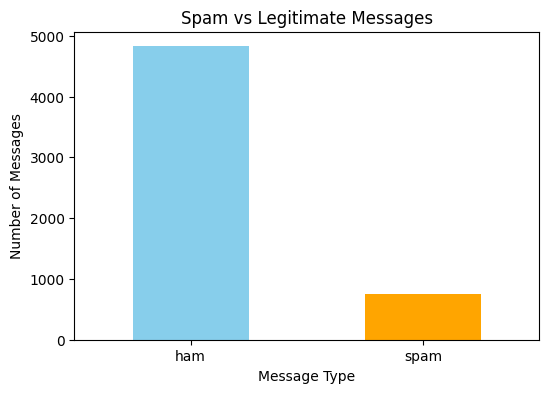

In [5]:
plt.figure(figsize=(6, 4))

label_counts.plot(
    kind="bar",
    color=["skyblue", "orange"]
)

plt.title("Spam vs Legitimate Messages")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.show()

### Understand what we calculated

We calculated:

$$
P(\text{Spam})=\frac{\text{Spam messages}}{\text{Total messages}}
$$

This is called the prior probability. It tells us how likely a randomly selected message is to be spam before examining its words.


### 5. Prepare the data

In [6]:
# Convert spam and ham labels into numbers
df["label_num"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    df["message"],
    df["label_num"],
    test_size=0.20,
    random_state=42,
    stratify=df["label_num"]
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Training messages: 4457
Testing messages: 1115


**Training and Testing Data**

I divided the dataset into two parts:

* 80% training data: 4,457 messages.
* 20% testing data: 1,115 messages.

The training data teaches the model to recognize spam and legitimate messages. The testing data evaluates how well the model works on messages it has not seen before.

I used stratified splitting to maintain approximately the same proportion of spam and legitimate messages in both groups.

### 6. Add training-only prior probabilities

In [7]:
# Calculate prior probabilities using training data only

p_spam_train = (y_train == 1).mean()
p_ham_train = (y_train == 0).mean()

print("Training Spam Prior:", round(p_spam_train, 3))
print("Training Legitimate Prior:", round(p_ham_train, 3))

Training Spam Prior: 0.134
Training Legitimate Prior: 0.866


### 7. Train the Naive Bayes model

In [9]:
# Convert text into word counts
vectorizer = CountVectorizer()

X_train_counts = vectorizer.fit_transform(X_train)
X_test_counts = vectorizer.transform(X_test)

# Train the probability model
model = MultinomialNB()
model.fit(X_train_counts, y_train)

print("Spam detection model trained successfully!")

Spam detection model trained successfully!


**How Naive Bayes Works**

My project uses the Naive Bayes classifier, which is based on Bayes' theorem.

$$P(Spam | Words) = P(Words | Spam) × P(Spam) / P(Words)$$

The model calculates the probability that a message is spam after examining its words.

It learns how frequently words appear in spam and legitimate messages. It then uses these learned probabilities to classify new messages.

Naive Bayes assumes that words are conditionally independent given the message category. This assumption simplifies the calculation.

 ### 8. Show the learned word probabilities

In [10]:
# Display learned word probabilities

feature_names = vectorizer.get_feature_names_out()
spam_log_probs = model.feature_log_prob_[1]
word_probabilities = pd.DataFrame({"Word": feature_names,"Spam Word Probability": np.exp(spam_log_probs)})

word_probabilities = word_probabilities.sort_values(by="Spam Word Probability",ascending=False)
print("Words with the highest spam probabilities:")
print(word_probabilities.head(15))

Words with the highest spam probabilities:
      Word  Spam Word Probability
6859    to               0.025912
1622  call               0.013002
7629   you               0.011250
7633  your               0.009959
2995  free               0.008345
2951   for               0.007700
6743   the               0.007654
4812   now               0.007193
4945    or               0.006870
3748    is               0.006317
7015   txt               0.006178
7126    ur               0.005487
3364  have               0.005118
3032  from               0.005072
4908    on               0.005026


**Learning Model Parameters**

The Naive Bayes model learns the probability of words appearing in spam messages from the training data.

I examined the learned word probabilities to understand which words are more strongly associated with spam.

The model also uses Laplace smoothing to avoid zero probabilities for words that were not observed in a particular category during training.

### 9. Test model

In [11]:
# Make predictions on the test set
predictions = model.predict(X_test_counts)

# Calculate accuracy
accuracy = accuracy_score(y_test, predictions)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["Legitimate", "Spam"]
))

Model Accuracy: 98.74 %

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.99      1.00      0.99       966
        Spam       0.99      0.92      0.95       149

    accuracy                           0.99      1115
   macro avg       0.99      0.96      0.97      1115
weighted avg       0.99      0.99      0.99      1115



### 10. Add a baseline comparison

In [12]:
# Baseline: Always predict legitimate
baseline_predictions = np.zeros(len(y_test), dtype=int)
baseline_accuracy = accuracy_score(y_test,baseline_predictions)
print("Baseline Accuracy:",round(baseline_accuracy * 100, 2), "%")
print("Naive Bayes Accuracy:",round(accuracy * 100, 2), "%")

Baseline Accuracy: 86.64 %
Naive Bayes Accuracy: 98.74 %


**Comparing Against a Simple Baseline**

I compared my Naive Bayes model with a simple baseline model that always predicts that a message is legitimate.

The baseline achieves approximately 86.6% accuracy because most messages in the dataset are legitimate.

My Naive Bayes model achieves 98.74% accuracy, showing that it performs better than simply predicting the majority category.

### 11. Understand model performance

Understanding Model Performance

My model achieved:

- Accuracy: 98.74%
- Spam precision: 99%
- Spam recall: 92%
- Spam F1-score: 95%

The most important result is spam recall.

A recall of 92% means the model detected approximately 92 out of every 100 actual spam messages in the test dataset.

However, some spam messages were missed. This demonstrates that the model is not perfect.



### 12. Confusion matrix

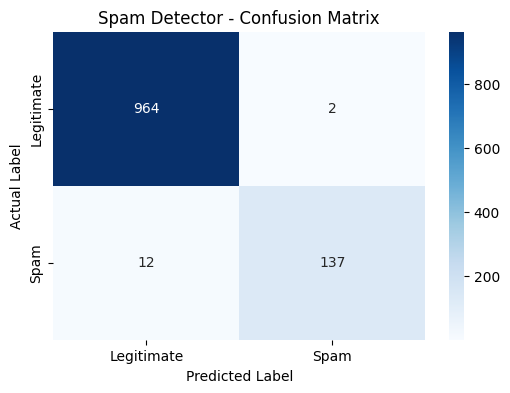

Correct legitimate: 964
False spam alerts: 2
Missed spam: 12
Correct spam: 137


In [13]:
cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=["Legitimate", "Spam"],yticklabels=["Legitimate", "Spam"])
plt.title("Spam Detector - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

# Extract the four values
tn, fp, fn, tp = cm.ravel()
print("Correct legitimate:", tn)
print("False spam alerts:", fp)
print("Missed spam:", fn)
print("Correct spam:", tp)

### 13. Probability chart
This chart compares the probability of spam and legitimate messages.

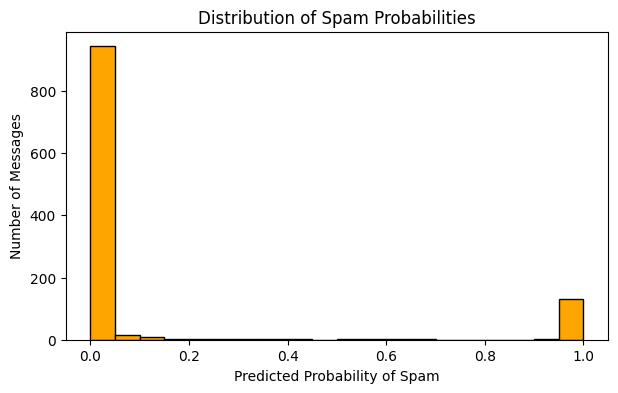

In [14]:
probabilities = model.predict_proba(X_test_counts)

plt.figure(figsize=(7, 4))

plt.hist(
    probabilities[:, 1],
    bins=20,
    color="orange",
    edgecolor="black"
)

plt.title("Distribution of Spam Probabilities")
plt.xlabel("Predicted Probability of Spam")
plt.ylabel("Number of Messages")
plt.show()

### 14. Test messages

In [16]:
# Make own spam detector
def check_message(message):
    message_counts = vectorizer.transform([message])
    prediction = model.predict(message_counts)[0]
    probabilities = model.predict_proba(message_counts)[0]
    spam_probability = probabilities[1]
    print("Message:", message)
    if prediction == 1:
        print("Prediction: SPAM")
    else:
        print("Prediction: LEGITIMATE")

    print("Probability of Spam:",
          round(spam_probability * 100, 2), "%")


# Try an example
check_message("Congratulations! You won a free prize. Click here now!")

Message: Congratulations! You won a free prize. Click here now!
Prediction: SPAM
Probability of Spam: 100.0 %


##### Try another message

In [17]:
check_message("Hello, how are you? Let's meet tomorrow.")

Message: Hello, how are you? Let's meet tomorrow.
Prediction: LEGITIMATE
Probability of Spam: 0.0 %


**Testing New Messages**

I created a function that allows users to enter their own SMS messages.

The model predicts whether each message is spam or legitimate and displays its estimated spam probability.

These predictions demonstrate how the trained model can be applied to new messages. However, predicted probabilities are estimates and should not be interpreted as guaranteed certainty.

### 15. Limitations

Although my model achieved high accuracy, it has some limitations:

1. Some spam messages may be incorrectly classified as legitimate.
2. Some legitimate messages may be incorrectly classified as spam.
3. The model mainly relies on word patterns and does not fully understand the meaning or context of messages.
4. New spam messages may contain words that were not present in the training dataset.
5. Naive Bayes assumes conditional independence between words, which is not always realistic in natural language.
6. High predicted probabilities do not guarantee that a classification is correct.

The project could be improved in the future by using a larger and more diverse dataset.

### Final results

In [18]:
results = {
    "Total Messages": total,
    "Training Messages": len(X_train),
    "Testing Messages": len(X_test),
    "Model Accuracy (%)": round(accuracy * 100, 2),
    "Baseline Accuracy (%)": round(baseline_accuracy * 100, 2),
    "Spam Recall (%)": round(100 * tp / (tp + fn), 2)}

print("===== PAI FINAL PROJECT RESULTS =====")

for key, value in results.items():
    print(key + ":", value)

===== PAI FINAL PROJECT RESULTS =====
Total Messages: 5572
Training Messages: 4457
Testing Messages: 1115
Model Accuracy (%): 98.74
Baseline Accuracy (%): 86.64
Spam Recall (%): 91.95
